# 04 · FitzHugh–Nagumo: recovery, excitability, and slow–fast oscillations
## Goal
Establish the single-neuron dynamics of a two-variable excitable model before coupling neurons. This follows the theta/QIF and Hopf notebooks, adding a recovery variable and a cubic nullcline.

**Questions:** Where are the equilibria and how do they change stability? When does a finite pulse trigger an isolated excursion? How does recovery affect a second pulse? Can rest coexist with repetitive oscillation? How do periods change with time-scale separation?

**Scope:** deterministic, dimensionless, illustrative parameters; no fitted membrane voltage/current, physical timescale, noise, resets, synapses, or network behavior. FitzHugh–Nagumo is a phenomenological model, not one universal bifurcation normal form. Excitability and bifurcation claims below apply to the specified equations and parameters.

All numerical data are generated here. Figures, tables, and a machine-readable summary are saved under `results/fhn/` relative to the execution directory and embedded in the notebook. No external data or internet connection are needed to rerun it.

## Setup
### Model convention and experiment parameters
$$\dot v=v-\frac{v^3}{3}-w+I(t),\qquad
\dot w=\epsilon(v+a-bw),$$
$$a=0.7,\qquad b=0.8,\qquad\epsilon=0.08.$$
$v$ is activation/voltage-like and $w$ recovery-like. All coordinates, input, and time are dimensionless. Frequencies are cycles per model-time unit, **not Hz**. $I$ is an abstract model input; no identification with a measured current is made. Smaller $\epsilon$ slows recovery relative to the fast equation.

The catalog uses this convention. The [Neuronal Dynamics phase-plane chapter](https://neuronaldynamics.epfl.ch/online/Ch4.S3.html) uses a related recovery convention $\epsilon_{book}(b_0+b_1v-w)$; it matches ours with $\epsilon_{book}=\epsilon b$, $b_0=a/b$, and $b_1=1/b$. Numerical parameters cannot be transferred between conventions without this change.

### Methods and assumptions
- Cartesian ODE integration; DOP853 default, Radau as an independent numerical reference. Tolerances, maximum steps, transients, and observation windows are explicit.
- A positive crossing of **$v=0$** is an operational large-excursion/spike event for these experiments. It is not the dynamical separatrix or a biological voltage threshold. Near-Hopf small oscillations may not cross this section and would require a different measurement protocol.
- Square-pulse discontinuities are handled by separate integration segments with continuous state. No reset or refractory hold is imposed.
- Equilibrium stability is analytic/numerical linearization; Hopf criticality is checked separately. No exact nonlinear period is assumed.
- The current scan uses two prescribed initial conditions at every current, not hidden noise or parameter continuation. Unsettled runs are labeled unresolved rather than assigned zero frequency.
- No random sampling. Errors are deterministic numerical discrepancies, not confidence intervals.

Use a Python kernel with NumPy, SciPy, pandas, Matplotlib, IPython, and Jupyter. Versions are recorded below; this notebook installs nothing.

In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import scipy
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

OUTPUT_DIR = Path('results')/'fhn'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
A_REC, B_REC, EPS = 0.7, 0.8, 0.08
COLORS = {'v': '#2166AC', 'w': '#C56A18', 'neutral': '#444444'}
plt.rcParams.update({'figure.figsize': (9.4, 4.3), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.18,
                     'figure.dpi': 110, 'savefig.dpi': 160})
pd.set_option('display.precision', 7)
VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__,
            'scipy': scipy.__version__, 'pandas': pd.__version__,
            'matplotlib': matplotlib.__version__}
print(VERSIONS)

def show_and_save(fig, stem):
    fig.savefig(OUTPUT_DIR/f'{stem}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)

def fhn_rhs(t, state, current, epsilon=EPS):
    v, w = state
    return np.array([v-v**3/3-w+current, epsilon*(v+A_REC-B_REC*w)])

def jacobian(state, epsilon=EPS):
    return np.array([[1-state[0]**2, -1.], [epsilon, -epsilon*B_REC]])

def current_of_equilibrium(v):
    return v**3/3+(1/B_REC-1)*v+A_REC/B_REC

def equilibrium(current):
    # For 0 < b < 1, dI/dv = v² + 1/b - 1 > 0: unique root.
    if not 0 < B_REC < 1:
        raise ValueError('This equilibrium helper assumes 0 < b < 1.')
    edge = 2.
    while current_of_equilibrium(-edge) > current or current_of_equilibrium(edge) < current:
        edge *= 2
    v = brentq(lambda x: current_of_equilibrium(x)-current, -edge, edge,
               xtol=1e-14, rtol=1e-14)
    return np.array([v, (v+A_REC)/B_REC])

def spike_event(t, state):
    return state[0]
spike_event.direction = 1
spike_event.terminal = False

def integrate(current, initial, duration, *, epsilon=EPS, start=0.,
              rtol=1e-9, atol=1e-11, method='DOP853', max_step=0.5):
    options = {}
    if method in ('Radau', 'BDF'):
        options['jac'] = lambda t, state: jacobian(state, epsilon)
    sol = solve_ivp(lambda t, state: fhn_rhs(t, state, current, epsilon),
                    (start, start+duration), initial, method=method,
                    rtol=rtol, atol=atol, max_step=max_step,
                    dense_output=True, events=spike_event, **options)
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol

REST = equilibrium(0.)
print('Baseline equilibrium (I=0):', REST)

{'python': '3.12.2', 'numpy': '2.2.6', 'scipy': '1.18.1', 'pandas': '3.0.6', 'matplotlib': '3.11.2'}
Baseline equilibrium (I=0): [-1.19940804 -0.62426004]


## Steps
### 1. Nullclines and equilibrium stability
The nullclines are
$$w=h(v;I)=v-v^3/3+I,\qquad w=(v+a)/b.$$
Their intersections solve
$$I(v_*)=v_*^3/3+(1/b-1)v_*+a/b.$$
For our $0<b<1$, $dI/dv_*=v_*^2+1/b-1>0$, so there is exactly **one equilibrium for every current**. Multiple-equilibrium FHN variants require a different parameter regime/convention.

At equilibrium,
$$J=\begin{pmatrix}1-v_*^2&-1\\\epsilon&-\epsilon b\end{pmatrix},\quad
\operatorname{tr}J=1-v_*^2-\epsilon b,\quad
\det J=\epsilon(1-b+bv_*^2)>0.$$
It is linearly stable when the trace is negative and unstable when positive. At zero trace, nonlinear analysis is needed.

The two trace-zero points are
$$v_H^\pm=\pm\sqrt{1-\epsilon b},\quad I_H^\pm=I(v_H^\pm),\quad
\omega_H=\sqrt{\epsilon(1-\epsilon b^2)}.$$
Here $1-\epsilon b>0$, $\omega_H>0$, and
$$\frac{d\operatorname{Re}\lambda}{dI}\bigg|_H
=-\frac{v_H}{v_H^2+1/b-1}\ne0.$$
Thus the imaginary eigenvalues cross transversely. Criticality is checked in Step 2.

The cubic folds at $v=\pm1$ concern the **fast subsystem with frozen $w$**. They are not equilibrium saddle-nodes of this full system and not a universal full-system excitation threshold.

,I_H,v_H,w_H,trace_J,det_J,linear_frequency,crossing_slope
0,0.3312813,-0.9674709,-0.3343387,2.7755576e-16,0.075904,0.0438483,0.8157428
1,1.4187187,0.9674709,2.0843387,4.9960036e-16,0.075904,0.0438483,-0.8157428


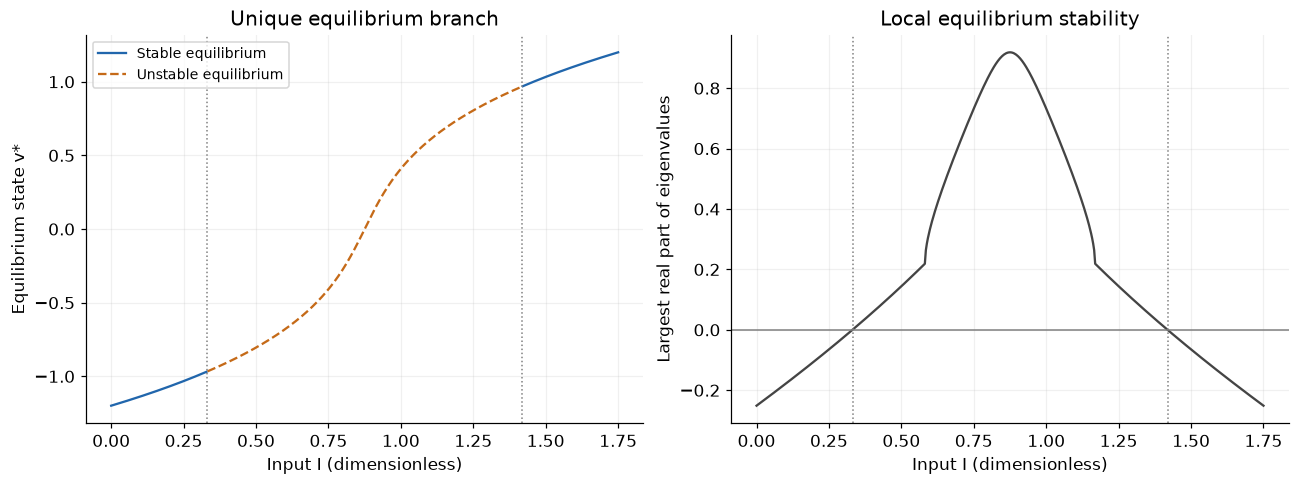

In [3]:
v_hopf = np.array([-np.sqrt(1-EPS*B_REC), np.sqrt(1-EPS*B_REC)])
I_H_LOW, I_H_HIGH = current_of_equilibrium(v_hopf)
OMEGA_H = np.sqrt(EPS*(1-EPS*B_REC**2))
hopf_rows = []
for v, current in zip(v_hopf, [I_H_LOW, I_H_HIGH]):
    point = equilibrium(current)
    J = jacobian(point)
    hopf_rows.append({'I_H': current, 'v_H': v, 'w_H': point[1],
                      'trace_J': np.trace(J), 'det_J': np.linalg.det(J),
                      'linear_frequency': OMEGA_H/(2*np.pi),
                      'crossing_slope': -v/(v*v+1/B_REC-1)})
hopf_table = pd.DataFrame(hopf_rows)
hopf_table.to_csv(OUTPUT_DIR/'hopf_points.csv', index=False)
display(hopf_table)

equilibrium_rows = []
for current in np.linspace(0, 1.75, 501):
    point = equilibrium(current)
    eig = np.linalg.eigvals(jacobian(point))
    equilibrium_rows.append({'I': current, 'v_eq': point[0], 'w_eq': point[1],
                             'max_real_eigenvalue': float(eig.real.max()),
                             'stable': bool(eig.real.max() < 0)})
equilibrium_table = pd.DataFrame(equilibrium_rows)
equilibrium_table.to_csv(OUTPUT_DIR/'equilibrium_stability.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(11.7, 4.3), layout='constrained')
for stable, color, style in [(True, COLORS['v'], '-'), (False, COLORS['w'], '--')]:
    yy = equilibrium_table.v_eq.where(equilibrium_table.stable == stable)
    axes[0].plot(equilibrium_table.I, yy, style, color=color,
                  label='Stable equilibrium' if stable else 'Unstable equilibrium')
axes[1].plot(equilibrium_table.I, equilibrium_table.max_real_eigenvalue,
              color=COLORS['neutral'])
axes[1].axhline(0, color='0.5', linewidth=1)
for ax in axes:
    for current in [I_H_LOW, I_H_HIGH]:
        ax.axvline(current, color='0.5', linestyle=':', linewidth=1)
    ax.set_xlabel('Input I (dimensionless)')
axes[0].set(ylabel='Equilibrium state v*', title='Unique equilibrium branch')
axes[0].legend(fontsize=9, loc='upper left')
axes[1].set(ylabel='Largest real part of eigenvalues', title='Local equilibrium stability')
show_and_save(fig, '01_equilibrium_stability')

### 2. Hopf criticality: do not infer it from a trace crossing
At a Hopf point let $X=v-v_H$, $d=\epsilon b$, and
$$Y=\frac{w-w_H-dX}{\omega_H}.$$
The shifted equations take the canonical linear rotation form
$$\dot X=-\omega_HY+n(X),\qquad
\dot Y=\omega_HX-\frac d{\omega_H}n(X),\qquad
n(X)=-v_HX^2-X^3/3.$$
The planar cubic amplitude coefficient in this coordinate normalization is
$$L=\frac{2b-1-\epsilon b^2}{8(1-\epsilon b^2)}.$$
One way to obtain it is to insert the derivatives of the two nonlinear terms into the planar Hopf formula: $-1/8+d v_H^2/(4\omega_H^2)$. For our parameters $L>0$, so both local Hopf bifurcations are **subcritical in the linear-growth-rate coordinate**. Increasing $I$ destabilizes the low-current equilibrium and stabilizes the high-current equilibrium because the crossing slopes have opposite signs.

For an independent sign check, the code below also evaluates the complex-eigenvector multilinear formula. Its numerical coefficient uses a different amplitude normalization, so its magnitude need not equal $L$. A positive sign identifies unstable small cycles locally; it does **not** locate the folds or stable large cycles globally. Those require further analysis/continuation. The finite current scan below tests selected attractors without claiming an exhaustive bifurcation diagram.

In [5]:
def complex_hopf_coefficient(vh):
    J = jacobian(np.array([vh, (vh+A_REC)/B_REC]))
    vals, vectors = np.linalg.eig(J)
    q = vectors[:, np.argmin(abs(vals-1j*OMEGA_H))]
    vals_left, vectors_left = np.linalg.eig(J.T)
    p = vectors_left[:, np.argmin(abs(vals_left+1j*OMEGA_H))]
    p = p/np.conj(np.vdot(p, q))
    def B(u, v):
        return np.array([-2*vh*u[0]*v[0], 0], dtype=complex)
    def C(u, v, w):
        return np.array([-2*u[0]*v[0]*w[0], 0], dtype=complex)
    value = np.vdot(p, C(q, q, q.conj())
                    -2*B(q, np.linalg.solve(J, B(q, q.conj())))
                    +B(q.conj(), np.linalg.solve(2j*OMEGA_H*np.eye(2)-J, B(q, q))))
    return float(value.real/(2*OMEGA_H)), float(abs(np.vdot(p, q)-1))

planar_hopf_coefficient = (2*B_REC-1-EPS*B_REC**2)/(8*(1-EPS*B_REC**2))
complex_coefficients = [complex_hopf_coefficient(v) for v in v_hopf]
print(f'Planar amplitude coefficient L: {planar_hopf_coefficient:.9f}')
print('Complex-eigenvector coefficients:', [c[0] for c in complex_coefficients])
assert planar_hopf_coefficient > 0
assert all(c[0] > 0 for c in complex_coefficients)

Planar amplitude coefficient L: 0.072301855
Complex-eigenvector coefficients: [0.9719710819889978, 0.9719710819889978]


### 3. Phase portraits and autonomous regimes
Compare $I=0$ (rest), $I=0.5$ (repetitive large excursions), and $I=1.7$ (stable high-$v$ equilibrium). The last is an abstract high-activation rest state, not an experimentally established depolarization block.

Nullclines and normalized flow directions organize the trajectories. Normalized arrows show direction, **not velocity magnitude**. The cubic's outer branches are attracting for the fast frozen-$w$ subsystem; its middle branch is repelling. Slow drift along outer branches and rapid jumps become more distinct as $\epsilon$ decreases.

All trajectories below start at $(v,w)=(2,-0.5)$ and run to $t=180$. The equilibrium marker is filled when stable and open when unstable. Phase-plane limits and time windows are common across panels.

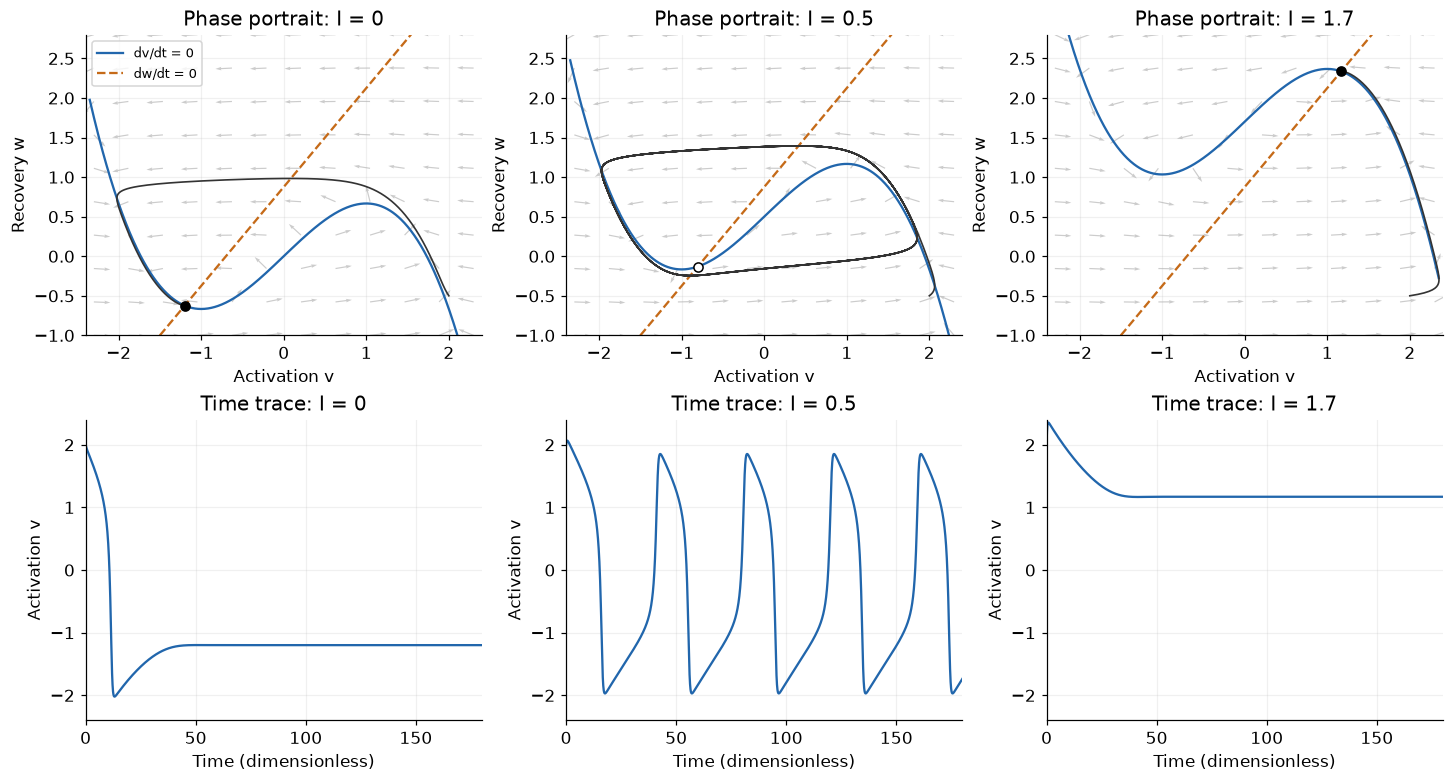

In [7]:
regime_solutions = {}
fig, axes = plt.subplots(2, 3, figsize=(13.1, 7.0), layout='constrained')
vgrid = np.linspace(-2.35, 2.35, 700)
for column, current in enumerate([0., 0.5, 1.7]):
    sol = integrate(current, [2, -0.5], 180.)
    regime_solutions[current] = sol
    tt = np.linspace(0, 180, 5001)
    xy = sol.sol(tt)
    ax = axes[0, column]
    ax.plot(vgrid, vgrid-vgrid**3/3+current, color=COLORS['v'], label='dv/dt = 0')
    ax.plot(vgrid, (vgrid+A_REC)/B_REC, '--', color=COLORS['w'], label='dw/dt = 0')
    gx, gy = np.meshgrid(np.linspace(-2.3, 2.3, 12), np.linspace(-1, 2.8, 10))
    dx, dy = fhn_rhs(0, [gx, gy], current)
    norm = np.hypot(dx, dy)
    ax.quiver(gx, gy, dx/np.maximum(norm, 1e-15), dy/np.maximum(norm, 1e-15),
               color='0.8', scale=24, width=0.003)
    ax.plot(*xy, color='0.2', linewidth=1.1)
    point = equilibrium(current)
    stable = np.linalg.eigvals(jacobian(point)).real.max() < 0
    ax.plot(*point, 'o', mec='black', mfc='black' if stable else 'white', markersize=6)
    ax.set(xlabel='Activation v', ylabel='Recovery w', title=f'Phase portrait: I = {current:g}',
            xlim=(-2.4, 2.4), ylim=(-1, 2.8))
    if column == 0:
        ax.legend(fontsize=8.5, loc='upper left')
    axes[1, column].plot(tt, xy[0], color=COLORS['v'])
    axes[1, column].set(xlabel='Time (dimensionless)', ylabel='Activation v',
                        title=f'Time trace: I = {current:g}', xlim=(0, 180), ylim=(-2.4, 2.4))
show_and_save(fig, '02_phase_portraits_and_regimes')

**Interpretation:** the recovery variable changes the trajectory's return path. At intermediate current the two variables sustain a relaxation oscillation; at the selected lower/higher currents these initial conditions settle to rest. These examples do not prove that every stable-equilibrium regime is monostable.

### 4. Isolated pulse-triggered excursions
Start at exact $I=0$ rest. Apply $I=0.2$ or $I=1.0$ during $10\leq t<11$, then return to baseline. Record positive $v=0$ events, peak $v$ on a dense display grid, and distance to the baseline equilibrium at $t=250$. Event times are interpolated by the solver, not inferred from plotted samples. Peak values are sampled estimates.

A cubic fold is not used as a global threshold. The pulse amplitude/duration, starting recovery state, and the operational event section jointly define this experiment. In this regime an excursion can return automatically to rest without an imposed reset.

,pulse_amplitude,duration,n_spikes,first_spike_time,sampled_peak_v,final_distance_to_rest
0,0.2,1.0,0,NaN,-1.0289512,9.4857497e-16
1,1.0,1.0,1,11.2026812,1.7824902,1.8073121e-15


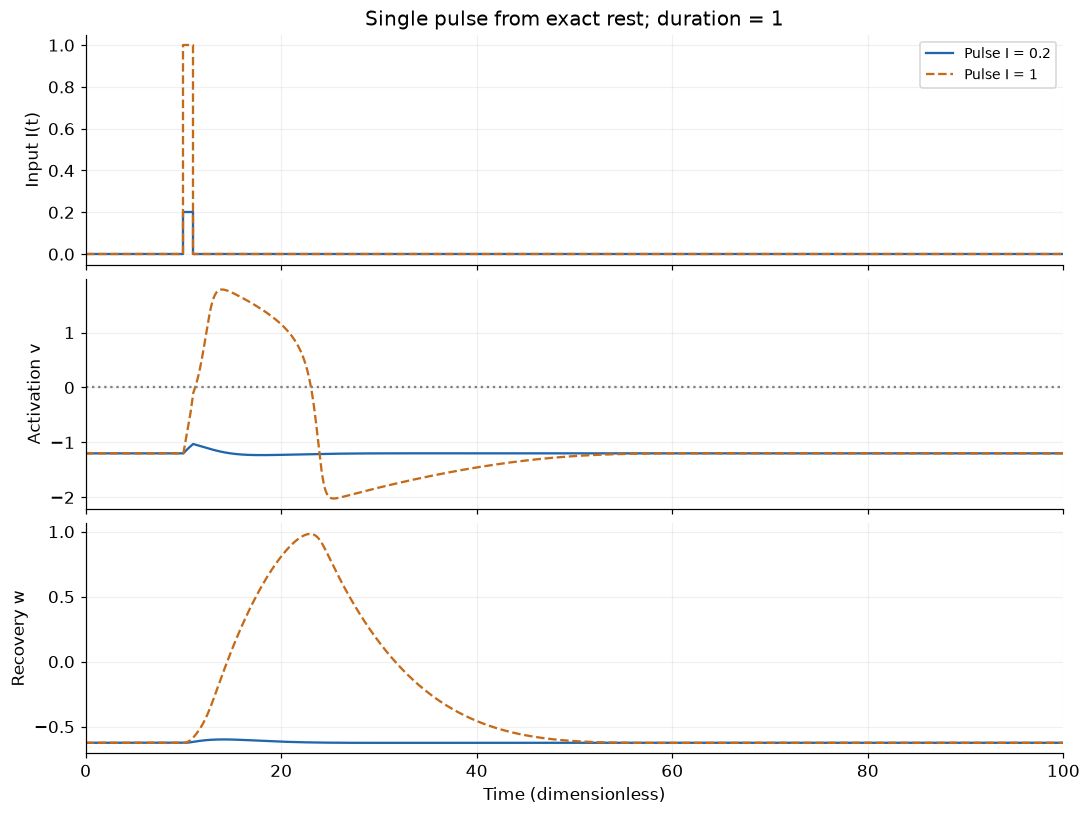

In [9]:
def protocol_integrate(segments, initial, **options):
    solutions, all_spikes = [], []
    state = np.asarray(initial, dtype=float)
    previous_stop = None
    for start, stop, current in segments:
        if previous_stop is not None and not np.isclose(start, previous_stop):
            raise ValueError('Protocol segments must be contiguous.')
        sol = integrate(current, state, stop-start, start=start, **options)
        solutions.append(sol)
        all_spikes.append(sol.t_events[0])
        state = sol.y[:, -1]
        previous_stop = stop
    spikes = np.concatenate(all_spikes)
    if len(spikes):
        spikes = spikes[np.r_[True, np.diff(spikes) > 1e-8]]
    return solutions, spikes

def sample_protocol(solutions, times):
    values = np.full((2, len(times)), np.nan)
    for sol in solutions:
        mask = (times >= sol.t[0]) & (times <= sol.t[-1])
        values[:, mask] = sol.sol(times[mask])
    if not np.isfinite(values).all():
        raise ValueError('Sample time outside protocol.')
    return values

PULSE_ON, PULSE_DURATION, PULSE_STOP = 10., 1., 250.
pulse_runs, pulse_rows = {}, []
pulse_times = np.linspace(0, PULSE_STOP, 10001)
for amplitude in [0.2, 1.]:
    segments = [(0, PULSE_ON, 0), (PULSE_ON, PULSE_ON+PULSE_DURATION, amplitude),
                 (PULSE_ON+PULSE_DURATION, PULSE_STOP, 0)]
    solutions, spikes = protocol_integrate(segments, REST)
    sampled = sample_protocol(solutions, pulse_times)
    pulse_runs[amplitude] = (solutions, spikes, sampled)
    pulse_rows.append({'pulse_amplitude': amplitude, 'duration': PULSE_DURATION,
                       'n_spikes': len(spikes),
                       'first_spike_time': float(spikes[0]) if len(spikes) else np.nan,
                       'sampled_peak_v': float(sampled[0].max()),
                       'final_distance_to_rest': float(np.linalg.norm(solutions[-1].y[:, -1]-REST))})
pulse_table = pd.DataFrame(pulse_rows)
pulse_table.to_csv(OUTPUT_DIR/'single_pulse_responses.csv', index=False)
display(pulse_table)
fig, axes = plt.subplots(3, 1, figsize=(9.8, 7.3), sharex=True, layout='constrained')
for amplitude, style, color in [(0.2, '-', COLORS['v']), (1., '--', COLORS['w'])]:
    solutions, spikes, sampled = pulse_runs[amplitude]
    axes[0].step([0, PULSE_ON, PULSE_ON+PULSE_DURATION, 100], [0, amplitude, 0, 0],
                 where='post', linestyle=style, color=color, label=f'Pulse I = {amplitude:g}')
    axes[1].plot(pulse_times, sampled[0], style, color=color)
    axes[2].plot(pulse_times, sampled[1], style, color=color)
axes[0].set(ylabel='Input I(t)', title='Single pulse from exact rest; duration = 1')
axes[0].legend(fontsize=9, loc='upper right')
axes[1].axhline(0, color='0.5', linestyle=':', label='Operational spike section')
axes[1].set_ylabel('Activation v')
axes[2].set(xlabel='Time (dimensionless)', ylabel='Recovery w', xlim=(0, 100))
show_and_save(fig, '03_single_pulse_excitation')

**Interpretation:** the stronger pulse produces a large excursion with delayed recovery and return to rest; the weaker pulse produces a small response. These two examples are not a complete strength–duration curve. The full-system excitation threshold is state/protocol dependent, not a fixed voltage number inferred from this plot.

### 5. Recovery tested by paired pulses
Use two identical amplitude-1, duration-1 pulses. The first begins at $t=10$; the second begins at $10+\Delta$, for $\Delta\in\{5,10,15,20,30,40,60,80\}$. Record the state immediately before the second pulse and count new positive $v=0$ crossings in the next 40 time units. For these gaps the first spike occurs before the second pulse; a separate single-pulse control has no later spikes.

This is an **operational recovery test at fixed stimulus strength**. A failed second response does not establish a universal absolute refractory period, and the first successful sampled gap is not an exact recovery threshold. The actual dynamics are continuous with no programmed refractory interval. Stronger or differently timed pulses can change the outcome.

,onset_gap,v_before_second,w_before_second,second_window_spikes,response_latency,total_spikes
0,5.0,1.7239156,0.0996604,0,NaN,1
1,10.0,1.1499555,0.8086445,0,NaN,1
2,15.0,-2.0048775,0.7880719,0,NaN,1
3,20.0,-1.8225952,0.1521154,0,NaN,1
4,30.0,-1.4560066,-0.4564643,0,NaN,1
5,40.0,-1.2492171,-0.6111026,1,1.4235242,2
6,60.0,-1.1991678,-0.6242690,1,1.2018938,2
7,80.0,-1.1994078,-0.6242605,1,1.2026788,2


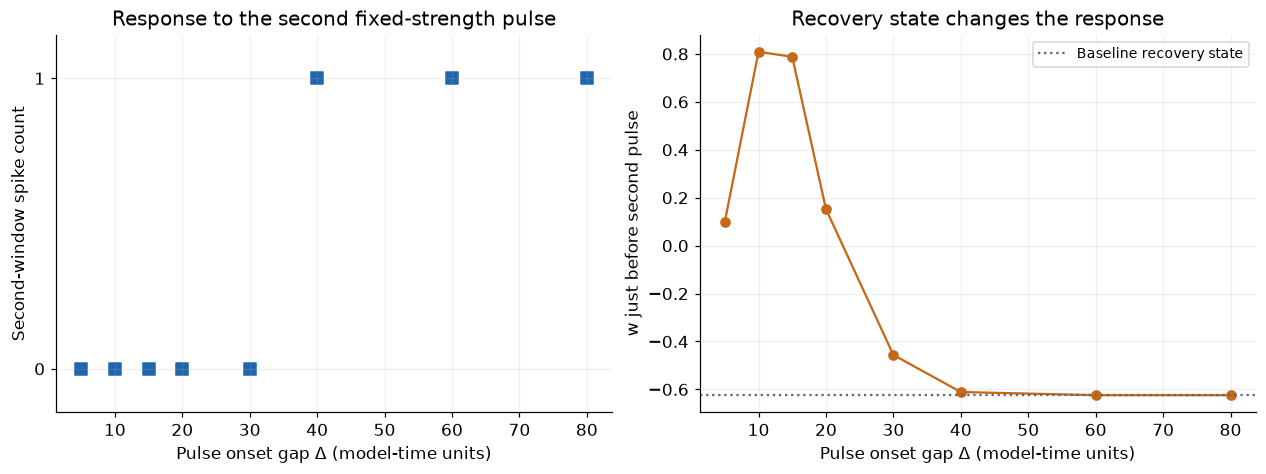

In [11]:
paired_rows = []
for gap in [5., 10., 15., 20., 30., 40., 60., 80.]:
    second_on = PULSE_ON+gap
    segments = [(0, 10, 0), (10, 11, 1), (11, second_on, 0),
                 (second_on, second_on+1, 1), (second_on+1, 250, 0)]
    solutions, spikes = protocol_integrate(segments, REST)
    before = solutions[2].y[:, -1]
    second_events = spikes[(spikes >= second_on) & (spikes < second_on+40)]
    paired_rows.append({'onset_gap': gap, 'v_before_second': before[0],
                        'w_before_second': before[1], 'second_window_spikes': len(second_events),
                        'response_latency': float(second_events[0]-second_on) if len(second_events) else np.nan,
                        'total_spikes': len(spikes)})
paired_table = pd.DataFrame(paired_rows)
paired_table.to_csv(OUTPUT_DIR/'paired_pulse_recovery.csv', index=False)
display(paired_table)
fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.2), layout='constrained')
axes[0].scatter(paired_table.onset_gap, paired_table.second_window_spikes,
                 marker='s', s=55, color=COLORS['v'])
axes[0].set(xlabel='Pulse onset gap Δ (model-time units)', ylabel='Second-window spike count',
            title='Response to the second fixed-strength pulse', yticks=[0, 1], ylim=(-0.15, 1.15))
axes[1].plot(paired_table.onset_gap, paired_table.w_before_second, 'o-', color=COLORS['w'])
axes[1].axhline(REST[1], color='0.4', linestyle=':', label='Baseline recovery state')
axes[1].set(xlabel='Pulse onset gap Δ (model-time units)', ylabel='w just before second pulse',
            title='Recovery state changes the response')
axes[1].legend(fontsize=9, loc='upper right')
show_and_save(fig, '04_paired_pulse_recovery')

### 6. Finite current scan: rest and repetitive large excursions
Test 18 specified currents with two independent initial conditions at each: equilibrium plus $(10^{-3},0)$, and $(2,-0.5)$. Integrate initially for 2000 time units. If not settled, rerun from the same initial condition for 4000, then 8000. This is **not** stable/unstable periodic-orbit continuation and does not locate cycle folds precisely.

Classification:
- **Rest:** the equilibrium is stable, final distance is below $10^{-6}$, and maximum distance over the last 200 time units is below $10^{-5}$.
- **Large cycle:** at least 6 recent positive $v=0$ crossings, last 5 ISIs have CV below $10^{-6}$, successive section states differ by less than $10^{-6}$, and the last event is within $1.5$ measured periods of the run's end.
- **Unresolved:** neither criterion; its rate is left missing. Small oscillations that do not cross $v=0$ are outside this large-excursion classifier.

Cycle period is the mean of the last 5 ISIs. Reported extrema use 2001 dense samples over the last complete cycle, not analytic amplitude bounds. Rest frequency is zero under the operational event convention. Different initial conditions revealing two settled outcomes provide evidence of coexistence at those tested currents, not a complete basin map.

Currents with both settled outcomes for these initial conditions: [0.325, 0.33, 1.42, 1.425]
Unresolved runs: 0


,I,initial_condition,outcome,period,frequency,duration
8,0.325,near equilibrium,rest,NaN,0.0000000,2000.0
9,0.325,large displacement,large cycle,51.8007455,0.0193047,2000.0
10,0.330,near equilibrium,rest,NaN,0.0000000,8000.0
11,0.330,large displacement,large cycle,48.8102101,0.0204875,2000.0
16,0.500,near equilibrium,large cycle,39.4744149,0.0253329,2000.0
17,0.500,large displacement,large cycle,39.4744149,0.0253329,2000.0
26,1.420,near equilibrium,rest,NaN,0.0000000,8000.0
27,1.420,large displacement,large cycle,48.8102101,0.0204875,2000.0
28,1.425,near equilibrium,rest,NaN,0.0000000,2000.0
29,1.425,large displacement,large cycle,51.8007455,0.0193047,2000.0


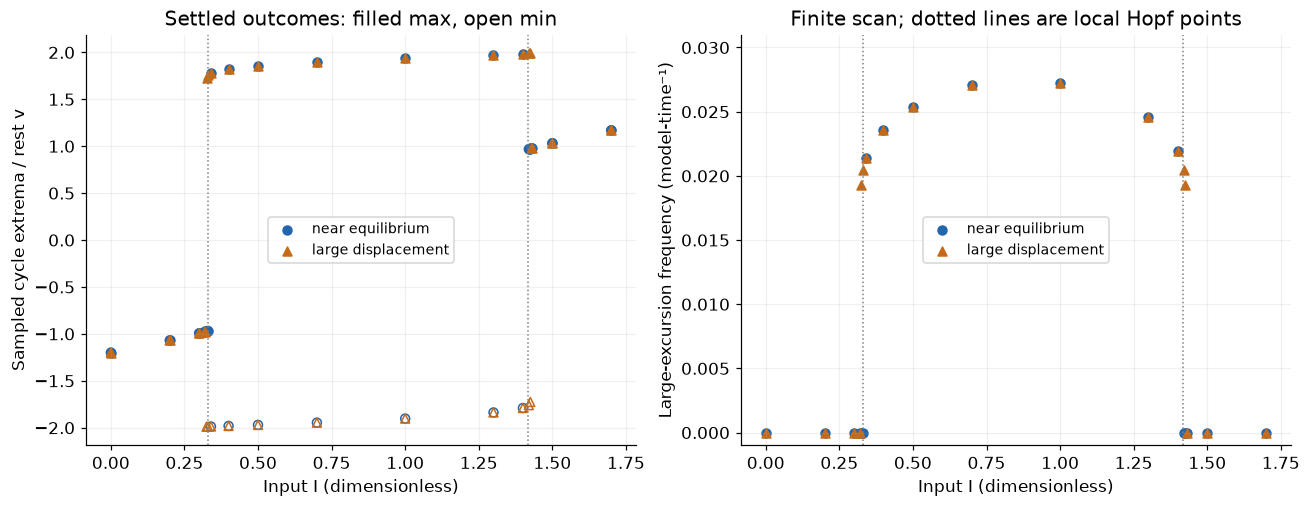

In [13]:
SCAN_CURRENTS = [0., 0.2, 0.3, 0.32, 0.325, 0.33, 0.34, 0.4, 0.5,
                  0.7, 1., 1.3, 1.4, 1.42, 1.425, 1.43, 1.5, 1.7]

def classify_run(sol, current):
    eq = equilibrium(current)
    end = sol.t[-1]
    eig_stable = np.linalg.eigvals(jacobian(eq)).real.max() < 0
    tail = sol.sol(np.linspace(end-200, end, 1001))
    distances = np.linalg.norm(tail-eq[:, None], axis=0)
    if eig_stable and distances[-1] < 1e-6 and distances.max() < 1e-5:
        return {'outcome': 'rest', 'period': np.nan, 'frequency': 0.,
                'v_min': eq[0], 'v_max': eq[0], 'isi_cv': np.nan,
                'section_closure_error': np.nan}
    events, states = sol.t_events[0], sol.y_events[0]
    if len(events) >= 6:
        intervals = np.diff(events[-6:])
        period = float(intervals.mean())
        cv = float(intervals.std(ddof=0)/period)
        closure = float(np.max(np.linalg.norm(np.diff(states[-6:], axis=0), axis=1)))
        if cv < 1e-6 and closure < 1e-6 and end-events[-1] < 1.5*period:
            vv = sol.sol(np.linspace(events[-2], events[-1], 2001))[0]
            return {'outcome': 'large cycle', 'period': period, 'frequency': 1/period,
                    'v_min': float(vv.min()), 'v_max': float(vv.max()),
                    'isi_cv': cv, 'section_closure_error': closure}
    return {'outcome': 'unresolved', 'period': np.nan, 'frequency': np.nan,
            'v_min': np.nan, 'v_max': np.nan, 'isi_cv': np.nan,
            'section_closure_error': np.nan}

scan_rows = []
for current in SCAN_CURRENTS:
    for label, initial in [('near equilibrium', equilibrium(current)+[1e-3, 0]),
                            ('large displacement', [2., -0.5])]:
        for duration in [2000., 4000., 8000.]:
            sol = integrate(current, initial, duration, rtol=1e-8, atol=1e-10, max_step=1.)
            metrics = classify_run(sol, current)
            if metrics['outcome'] != 'unresolved':
                break
        scan_rows.append({'I': current, 'initial_condition': label,
                           'duration': duration, **metrics})
scan_table = pd.DataFrame(scan_rows)
scan_table.to_csv(OUTPUT_DIR/'current_scan.csv', index=False)
coexistence = []
for current, part in scan_table.groupby('I'):
    if set(part.outcome) == {'rest', 'large cycle'}:
        coexistence.append(float(current))
print('Currents with both settled outcomes for these initial conditions:', coexistence)
print('Unresolved runs:', int((scan_table.outcome == 'unresolved').sum()))
display(scan_table[scan_table.I.isin([0.325, 0.33, 0.5, 1.42, 1.425])][
    ['I', 'initial_condition', 'outcome', 'period', 'frequency', 'duration']])

fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.5), layout='constrained')
for label, color, marker in [('near equilibrium', COLORS['v'], 'o'),
                             ('large displacement', COLORS['w'], '^')]:
    part = scan_table[scan_table.initial_condition == label]
    axes[0].scatter(part.I, part.v_max, marker=marker, color=color, s=34, label=label)
    axes[0].scatter(part.I, part.v_min, marker=marker, facecolors='none', edgecolors=color, s=34)
    axes[1].scatter(part.I, part.frequency, marker=marker, color=color, s=34, label=label)
for ax in axes:
    for current in [I_H_LOW, I_H_HIGH]:
        ax.axvline(current, color='0.5', linestyle=':', linewidth=1)
    ax.set_xlabel('Input I (dimensionless)')
    ax.legend(fontsize=9, loc='center')
axes[0].set(ylabel='Sampled cycle extrema / rest v', title='Settled outcomes: filled max, open min')
axes[1].set(ylabel='Large-excursion frequency (model-time⁻¹)',
            title='Finite scan; dotted lines are local Hopf points', ylim=(-0.001, 0.031))
show_and_save(fig, '05_current_scan')

**Interpretation:** subcritical Hopf criticality permits local coexistence, but only settled numerical outcomes establish which selected currents support the observed large cycle. Do not equate a Hopf current with an exact large-cycle existence boundary. Resolving the unstable cycle and cycle folds requires dedicated periodic-orbit continuation. No asymptotic zero-frequency onset or universal FHN excitability class is inferred from this finite scan.

For bounded constant input, boundedness is consistent with the energy function
$$E=\tfrac12v^2+\frac{w^2}{2\epsilon},\qquad
\dot E=v^2-\tfrac13v^4+Iv+aw-bw^2.$$
The mixed $vw$ terms cancel; the negative quartic and negative $w^2$ terms dominate outside a sufficiently large compact set. Together with planar autonomous dynamics, this rules out interpreting an irregular-looking finite trace as an autonomous chaotic attractor under the usual smooth-flow assumptions.

### 7. Slow–fast dynamics and a singular period benchmark
Fix $I=0.5$ and vary $\epsilon\in\{0.08,0.04,0.02,0.01,0.005\}$. Each run starts at $(2,-0.5)$ and lasts $20/\epsilon$; measure the last 3 ISIs after $0.4T_{run}$. These horizons adapt to slow recovery, rather than using a fixed short window.

On the critical manifold $w=h(v;I)$ and slow time $\tau=\epsilon t$,
$$(1-v^2)\frac{dv}{d\tau}=v+a-bh(v;I).$$
In the singular relaxation cycle, the outer slow segments run from $v=-2$ to $-1$ and from $v=2$ to $1$; the ideal fast jumps connect cubic folds to the opposite outer branch at fixed $w$. For this $I$, the slow denominator has no zero on those segments. The leading slow-time period is
$$C(I)=\int_{-2}^{-1}\frac{1-v^2}{v+a-bh(v;I)}\,dv
+\int_{2}^{1}\frac{1-v^2}{v+a-bh(v;I)}\,dv,$$
so $\epsilon T\to C$ as $\epsilon\to0$. This is a **singular-limit approximation**, not an exact finite-$\epsilon$ period. Fold-passage delay and fast jumps cause finite-$\epsilon$ corrections.

,epsilon,period,scaled_period_epsilon_T,singular_C,relative_singular_discrepancy,last3_isi_cv,run_duration
0,0.080,39.4744150,3.1579532,1.9519649,0.6178330,5.8788024e-16,250.0
1,0.040,67.9507749,2.7180310,1.9519649,0.3924589,8.5909509e-13,500.0
2,0.020,122.1133538,2.4422671,1.9519649,0.2511839,3.0406147e-15,1000.0
3,0.010,226.6479871,2.2664799,1.9519649,0.1611274,5.5304058e-13,2000.0
4,0.005,430.7445515,2.1537228,1.9519649,0.1033614,8.8541114e-13,4000.0


Singular slow-time period C(I=0.5): 1.951964906


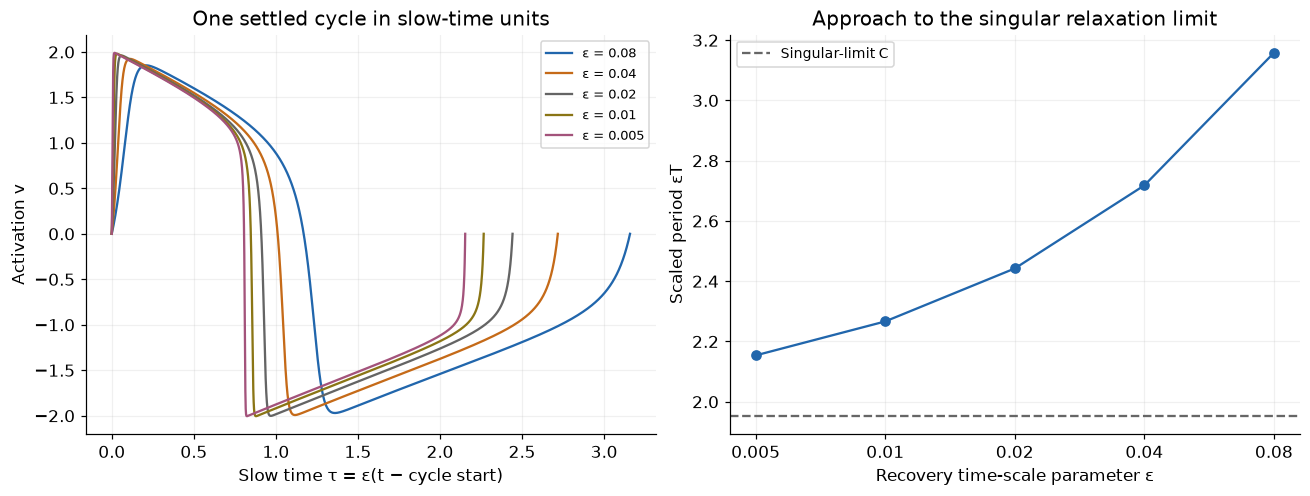

Singular-limit relative discrepancy: 61.78% at ε=0.08, 10.34% at ε=0.005.


In [15]:
SLOW_CURRENT = 0.5

def slow_integrand(v):
    h = v-v**3/3+SLOW_CURRENT
    return (1-v*v)/(v+A_REC-B_REC*h)

singular_period = quad(slow_integrand, -2, -1, epsabs=1e-12, epsrel=1e-12)[0]
singular_period += quad(slow_integrand, 2, 1, epsabs=1e-12, epsrel=1e-12)[0]
# Independent fixed-order Gauss-Legendre quadrature.
nodes, weights = np.polynomial.legendre.leggauss(96)
def gauss_integral(lo, hi):
    vv = (hi+lo)/2+(hi-lo)*nodes/2
    return float((hi-lo)/2*np.sum(weights*slow_integrand(vv)))
singular_period_gauss = gauss_integral(-2, -1)+gauss_integral(2, 1)
slow_rows, slow_cycles = [], {}
for epsilon in [0.08, 0.04, 0.02, 0.01, 0.005]:
    duration = 20/epsilon
    sol = integrate(SLOW_CURRENT, [2, -0.5], duration, epsilon=epsilon)
    events = sol.t_events[0]
    recent = events[events > 0.4*duration]
    if len(recent) < 4:
        raise RuntimeError('Insufficient post-transient cycles for slow-time benchmark.')
    intervals = np.diff(recent[-4:])
    period = float(intervals.mean())
    times = np.linspace(recent[-2], recent[-1], 2001)
    slow_cycles[epsilon] = (epsilon*(times-times[0]), sol.sol(times)[0])
    slow_rows.append({'epsilon': epsilon, 'period': period,
                      'scaled_period_epsilon_T': epsilon*period,
                      'singular_C': singular_period,
                      'relative_singular_discrepancy': abs(epsilon*period/singular_period-1),
                      'last3_isi_cv': float(intervals.std(ddof=0)/period),
                      'run_duration': duration})
slow_table = pd.DataFrame(slow_rows)
slow_table.to_csv(OUTPUT_DIR/'slow_fast_periods.csv', index=False)
display(slow_table)
print(f'Singular slow-time period C(I=0.5): {singular_period:.9f}')
fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.4), layout='constrained')
cycle_colors = ['#2166AC', '#C56A18', '#646464', '#8A7515', '#A3537B']
for (epsilon, (tau, vv)), color in zip(slow_cycles.items(), cycle_colors):
    axes[0].plot(tau, vv, color=color, label=f'ε = {epsilon:g}')
axes[0].set(xlabel='Slow time τ = ε(t − cycle start)', ylabel='Activation v',
            title='One settled cycle in slow-time units')
axes[0].legend(fontsize=8.5, loc='upper right')
axes[1].semilogx(slow_table.epsilon, slow_table.scaled_period_epsilon_T, 'o-', color=COLORS['v'])
axes[1].axhline(singular_period, color='0.4', linestyle='--', label='Singular-limit C')
axes[1].set(xlabel='Recovery time-scale parameter ε', ylabel='Scaled period εT',
            title='Approach to the singular relaxation limit')
axes[1].legend(fontsize=9, loc='upper left')
axes[1].set_xticks([0.005, 0.01, 0.02, 0.04, 0.08], ['0.005', '0.01', '0.02', '0.04', '0.08'])
axes[1].set_xticks([], minor=True)
show_and_save(fig, '06_slow_fast_periods')
print(f"Singular-limit relative discrepancy: {100*slow_table.relative_singular_discrepancy.iloc[0]:.2f}% at ε=0.08, "
      f"{100*slow_table.relative_singular_discrepancy.iloc[-1]:.2f}% at ε=0.005.")

**Interpretation of the slow–fast comparison:** decreasing ε improves the singular approximation, but even ε=0.005 retains a finite discrepancy. The tabulated singular-limit discrepancies measure approximation error of the reduced description, not numerical integration error.

### 8. Numerical convergence without an exact nonlinear period
At $I=0.5$, first relax for 600 time units, then initialize on the last positive $v=0$ section state. A tight Radau run over 200 additional units is the **numerical reference**, not an analytic truth. A tight DOP853 run with the same 0.1 maximum step cross-checks it.

For RK45 tolerances $10^{-4},10^{-6},10^{-8},10^{-10}$ (`atol = rtol/100`, maximum step 2), compare the mean of the last 3 ISIs with the Radau value, and compare the entire $v(t)$ trajectory at 4001 common times. The trajectory discrepancy includes accumulated phase error; it is not merely amplitude error. Solver event interpolation measures spike times. Agreement across methods plus tolerance improvement is stronger evidence than a visually smooth trace alone.

,rtol,period,relative_period_error,max_v_trajectory_error,nfev
0,1.0000000e-04,39.4765648,5.4459857e-05,1.4745344e-02,1496
1,1.0000000e-06,39.4744255,2.6739807e-07,7.2613902e-05,3374
2,1.0000000e-08,39.4744150,8.2870510e-10,2.8557597e-07,7628
3,1.0000000e-10,39.4744150,2.6135760e-12,2.7545914e-09,17060


Radau reference period at I=0.5: 39.4744149802
Tight DOP853 relative period difference: 8.993e-15


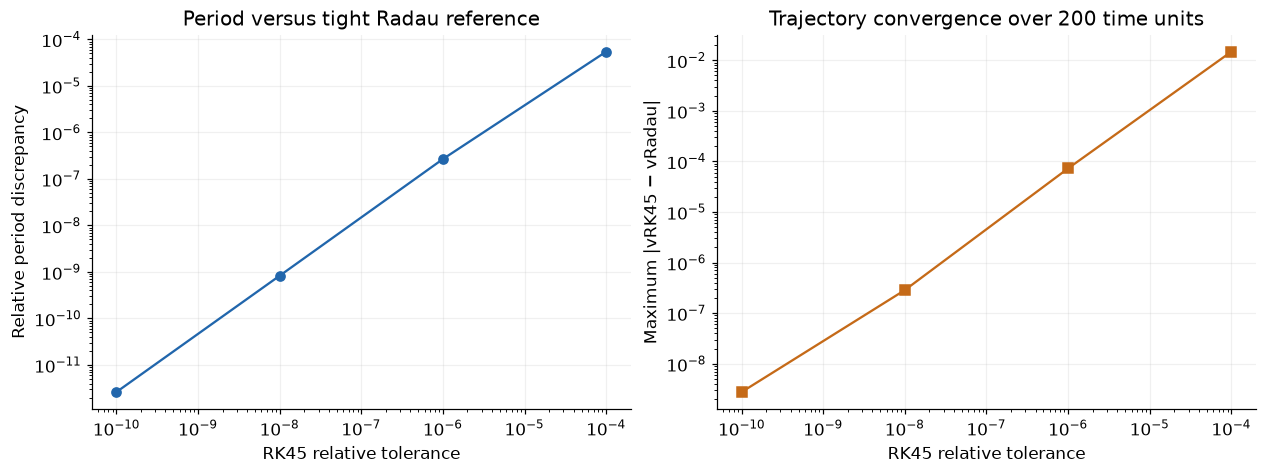

In [17]:
burn = integrate(0.5, [2, -0.5], 600., rtol=1e-11, atol=1e-13)
section_initial = burn.y_events[0][-1].copy()
section_initial[0] = 0.
reference = integrate(0.5, section_initial, 200., method='Radau',
                       rtol=1e-11, atol=1e-13, max_step=0.1)
ref_spikes = reference.t_events[0]
ref_spikes = ref_spikes[ref_spikes > 1e-7]
reference_period = float(np.diff(ref_spikes[-4:]).mean())
reference_closure = float(np.linalg.norm(reference.y_events[0][-1]-reference.y_events[0][-2]))
comparison_times = np.linspace(0, 200, 4001)
reference_v = reference.sol(comparison_times)[0]
method_comparison = integrate(0.5, section_initial, 200., rtol=1e-11, atol=1e-13, max_step=0.1)
method_spikes = method_comparison.t_events[0]
method_spikes = method_spikes[method_spikes > 1e-7]
method_period = float(np.diff(method_spikes[-4:]).mean())
method_relative_error = abs(method_period/reference_period-1)
convergence_rows = []
for tolerance in [1e-4, 1e-6, 1e-8, 1e-10]:
    sol = integrate(0.5, section_initial, 200., method='RK45', rtol=tolerance,
                    atol=tolerance/100, max_step=2.)
    spikes = sol.t_events[0]
    spikes = spikes[spikes > 1e-7]
    if len(spikes) < 4:
        raise RuntimeError('Insufficient cycles for solver comparison.')
    period = float(np.diff(spikes[-4:]).mean())
    convergence_rows.append({'rtol': tolerance, 'period': period,
                             'relative_period_error': abs(period/reference_period-1),
                             'max_v_trajectory_error': float(np.max(abs(sol.sol(comparison_times)[0]-reference_v))),
                             'nfev': sol.nfev})
convergence_table = pd.DataFrame(convergence_rows)
convergence_table.to_csv(OUTPUT_DIR/'solver_convergence.csv', index=False)
display(convergence_table)
print(f'Radau reference period at I=0.5: {reference_period:.10f}')
print(f'Tight DOP853 relative period difference: {method_relative_error:.3e}')
fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.2), layout='constrained')
axes[0].loglog(convergence_table.rtol, convergence_table.relative_period_error,
                'o-', color=COLORS['v'])
axes[0].set(xlabel='RK45 relative tolerance', ylabel='Relative period discrepancy',
            title='Period versus tight Radau reference')
axes[1].loglog(convergence_table.rtol, convergence_table.max_v_trajectory_error,
                's-', color=COLORS['w'])
axes[1].set(xlabel='RK45 relative tolerance', ylabel='Maximum |vRK45 − vRadau|',
            title='Trajectory convergence over 200 time units')
show_and_save(fig, '07_solver_convergence')

## Checks
### Declared numerical acceptance criteria
These checks compare equilibrium identities, derivatives, independent calculations, settled-cycle closure, and numerical methods. No analytic full-system period is claimed. Pulse counts and selected coexistence outcomes are additional assertions for these protocols, not universal FHN properties. Changes to parameters, thresholds, horizons, or methods require rerunning the checks.

In [19]:
equilibrium_residual = max(np.linalg.norm(fhn_rhs(0, equilibrium(current), current))
                            for current in SCAN_CURRENTS)
h = 1e-5
jacobian_error = 0.
for current in [0., 0.5, 1.7]:
    point = equilibrium(current)
    numerical_j = np.column_stack([
        (fhn_rhs(0, point+h*axis, current)-fhn_rhs(0, point-h*axis, current))/(2*h)
        for axis in np.eye(2)])
    jacobian_error = max(jacobian_error, float(np.max(abs(numerical_j-jacobian(point)))))
trace_error = float(np.max(abs(hopf_table.trace_J)))
frequency_error = 0.
crossing_slope_error = 0.
for current, analytic_slope in zip([I_H_LOW, I_H_HIGH], hopf_table.crossing_slope):
    eig = np.linalg.eigvals(jacobian(equilibrium(current)))
    frequency_error = max(frequency_error, float(max(abs(abs(eig.imag)-OMEGA_H))))
    delta = 1e-5
    # Complex-pair real part equals trace/2 in this local neighborhood.
    numerical_slope = (np.trace(jacobian(equilibrium(current+delta)))
                       -np.trace(jacobian(equilibrium(current-delta))))/(4*delta)
    crossing_slope_error = max(crossing_slope_error, abs(numerical_slope-analytic_slope))
checks = [
    ('Equilibrium residual across tested currents', equilibrium_residual, 1e-11),
    ('Analytic versus finite-difference Jacobian', jacobian_error, 1e-8),
    ('Trace zero at analytic Hopf points', trace_error, 1e-11),
    ('Hopf eigenvalue imaginary frequency', frequency_error, 1e-10),
    ('Hopf crossing slope versus finite difference', crossing_slope_error, 1e-7),
    ('Complex Hopf eigenvector normalization', max(c[1] for c in complex_coefficients), 1e-10),
    ('Pulse return-to-rest maximum endpoint distance', pulse_table.final_distance_to_rest.max(), 1e-8),
    ('Independent singular-period quadratures', abs(singular_period-singular_period_gauss), 1e-10),
    ('Slow-fast last3 maximum ISI CV', slow_table.last3_isi_cv.max(), 1e-5),
    ('Radau cycle section closure', reference_closure, 1e-8),
    ('Tight Radau versus DOP853 relative period', method_relative_error, 1e-8),
    ('Tight RK45 versus Radau relative period', convergence_table.relative_period_error.iloc[-1], 1e-7),
    ('Tight RK45 v trajectory discrepancy', convergence_table.max_v_trajectory_error.iloc[-1], 1e-5)]
check_table = pd.DataFrame(checks, columns=['check', 'observed_error', 'limit'])
check_table['passed'] = check_table.observed_error < check_table.limit
assert check_table.passed.all(), check_table.loc[~check_table.passed]
assert pulse_table.n_spikes.tolist() == [0, 1]
assert pulse_runs[1.][1][0] < PULSE_ON+5  # first event precedes earliest second pulse
assert paired_table.second_window_spikes.iloc[-1] == 1
assert convergence_table.relative_period_error.iloc[-1] < convergence_table.relative_period_error.iloc[0]
assert slow_table.relative_singular_discrepancy.iloc[-1] < slow_table.relative_singular_discrepancy.iloc[0]
assert np.all(hopf_table.det_J > 0)
assert all(abs(slope) > 0 for slope in hopf_table.crossing_slope)
assert planar_hopf_coefficient > 0 and all(c[0] > 0 for c in complex_coefficients)
assert 0.325 in coexistence and 1.425 in coexistence
check_table.to_csv(OUTPUT_DIR/'validation_checks.csv', index=False)
display(check_table)
print('All tabulated criteria and additional protocol assertions passed.')

,check,observed_error,limit,passed
0,Equilibrium residual across tested currents,1.1102230e-15,1.0000000e-11,True
1,Analytic versus finite-difference Jacobian,3.4612035e-11,1.0000000e-08,True
2,Trace zero at analytic Hopf points,4.9960036e-16,1.0000000e-11,True
3,Hopf eigenvalue imaginary frequency,1.1102230e-16,1.0000000e-10,True
4,Hopf crossing slope versus finite difference,1.3218759e-11,1.0000000e-07,True
5,Complex Hopf eigenvector normalization,6.4855625e-19,1.0000000e-10,True
6,Pulse return-to-rest maximum endpoint distance,1.8073121e-15,1.0000000e-08,True
7,Independent singular-period quadratures,1.3322676e-15,1.0000000e-10,True
8,Slow-fast last3 maximum ISI CV,8.8541114e-13,1.0000000e-05,True
9,Radau cycle section closure,1.9491264e-14,1.0000000e-08,True


All tabulated criteria and additional protocol assertions passed.


## Takeaways
The summary below is generated from the executed computations. Numerical agreement validates implementation of this mathematical convention; it does not validate biological calibration or imply that all FHN parameterizations share these dynamics.

In [21]:
responding_gaps = paired_table.loc[paired_table.second_window_spikes > 0, 'onset_gap'].tolist()
summary = {
    'versions': VERSIONS, 'units': 'dimensionless',
    'parameters': {'a': A_REC, 'b': B_REC, 'epsilon': EPS},
    'baseline_equilibrium': REST.tolist(),
    'lower_hopf_current': float(I_H_LOW), 'upper_hopf_current': float(I_H_HIGH),
    'hopf_linear_frequency': float(OMEGA_H/(2*np.pi)),
    'planar_hopf_coefficient': float(planar_hopf_coefficient),
    'sampled_coexistence_currents': coexistence,
    'unresolved_scan_runs': int((scan_table.outcome == 'unresolved').sum()),
    'reference_period_I_0p5': reference_period,
    'radau_dop853_relative_period_difference': float(method_relative_error),
    'single_pulse_spike_counts': pulse_table.n_spikes.tolist(),
    'paired_pulse_responding_sampled_gaps': responding_gaps,
    'singular_slow_time_period_I_0p5': float(singular_period),
    'accuracy_checks_passed': int(check_table.passed.sum())}
(OUTPUT_DIR/'summary.json').write_text(json.dumps(summary, indent=2)+'\n')
display(Markdown(f"""
- **Equilibrium:** unique for every I with these a,b; linearly stable for **I < {I_H_LOW:.6f}** or **I > {I_H_HIGH:.6f}**, unstable strictly between. The two endpoints are nonhyperbolic.
- **Hopf criticality:** planar amplitude coefficient **L = {planar_hopf_coefficient:.6f} > 0**; both local Hopf points are subcritical in growth-rate coordinates.
- **Rest/excursion:** duration-1 pulses of amplitudes **0.2** and **1.0** at baseline **I=0** produced **0** and **1** operational spikes and returned to rest.
- **Recovery:** responding sampled onset gaps for two amplitude-1 pulses were **{responding_gaps}**. These are protocol outcomes, not an exact biological refractory interval.
- **Coexistence:** the tested initial conditions settled to both rest and a large cycle at currents **{coexistence}**; **{summary['unresolved_scan_runs']}** scan runs remain unresolved.
- **Repetitive oscillation:** at **I=0.5**, the numerical reference period is **{reference_period:.6f}** model-time units; tight Radau/DOP853 relative difference **{method_relative_error:.2e}**.
- **Slow–fast limit:** singular slow-time period **C = {singular_period:.6f}**; finite-ε discrepancies are tabulated separately from solver errors.
- **Verification:** all **{len(check_table)}** tabulated numerical criteria and additional protocol assertions passed.
"""))


- **Equilibrium:** unique for every I with these a,b; linearly stable for **I < 0.331281** or **I > 1.418719**, unstable strictly between. The two endpoints are nonhyperbolic.
- **Hopf criticality:** planar amplitude coefficient **L = 0.072302 > 0**; both local Hopf points are subcritical in growth-rate coordinates.
- **Rest/excursion:** duration-1 pulses of amplitudes **0.2** and **1.0** at baseline **I=0** produced **0** and **1** operational spikes and returned to rest.
- **Recovery:** responding sampled onset gaps for two amplitude-1 pulses were **[40.0, 60.0, 80.0]**. These are protocol outcomes, not an exact biological refractory interval.
- **Coexistence:** the tested initial conditions settled to both rest and a large cycle at currents **[0.325, 0.33, 1.42, 1.425]**; **0** scan runs remain unresolved.
- **Repetitive oscillation:** at **I=0.5**, the numerical reference period is **39.474415** model-time units; tight Radau/DOP853 relative difference **8.99e-15**.
- **Slow–fast limit:** singular slow-time period **C = 1.951965**; finite-ε discrepancies are tabulated separately from solver errors.
- **Verification:** all **13** tabulated numerical criteria and additional protocol assertions passed.


## Next steps
**Next single-neuron extension: Hindmarsh–Rose.** Add a third slow variable and distinguish tonic spiking, bursting, and irregular activity through slow–fast analysis and convergence checks. This should precede assigning bursting nodes to networks. Alternatively, a dedicated FHN continuation notebook could resolve the unstable cycles and folds omitted here; that is separate work rather than a conclusion from finite time sweeps.

For future coupling, state whether input enters the $v$ equation, recovery equation, or explicit synaptic variables. Diffusive coupling of dimensionless activation variables is a mathematical interaction; calling it an electrical or chemical synapse requires an observation map, scaling, and channel conventions.

### References and provenance
- FitzHugh (1961), *Impulses and physiological states in theoretical models of nerve membrane*, Biophysical Journal 1, 445–466. [Original paper record and abstract](https://pubmed.ncbi.nlm.nih.gov/19431309/), [DOI](https://doi.org/10.1016/S0006-3495(61)86902-6). The original establishes the excitable/recovery-model context; numerical examples here use the explicitly stated modern convention.
- Gerstner, Kistler, Naud & Paninski (2014), *Neuronal Dynamics*, [§4.3: phase-plane analysis and FHN](https://neuronaldynamics.epfl.ch/online/Ch4.S3.html). Parameter-convention mapping is given in Setup. References accessed during preparation on 2026-10-26; project PDFs are not analyzed here.
- Kuznetsov, *Elements of Applied Bifurcation Theory*, 2nd ed., [textbook hosted at Imperial College](https://www.ma.imperial.ac.uk/~dturaev/kuznetsov.pdf), §§3.4–3.5 and Hopf-coefficient formulas, for local Hopf criteria and amplitude normalization. The particular FHN coefficient in Step 2 is computed from the displayed derivatives, with an independent sign calculation.
- [SciPy solve_ivp documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html), for adaptive integration and event interpolation; installed versions appear in Setup.

**Limitations:** no universal excitation voltage, biological refractory duration, physical firing rate, global FHN bifurcation classification, or chaotic attractor is inferred. The current scan tests only two initial conditions per current and one operational event section; no unstable periodic orbit or exact cycle-fold location is computed. The singular-period formula is asymptotic, whereas the Radau result is a numerical reference. The recovery protocol uses finite sampling in gap and fixed pulse strength. Normal-form coefficients describe local onset; large relaxation excursions require the full nonlinear equations.